In [5]:
# Importing necessary classes
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import boxcox
from scipy.special import inv_boxcox
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
import tensorflow as tf
import seaborn as sn


In [6]:
# Loading the dataset and shaping it into a time series dataset
rainfall= pd.read_csv('content/2619492.csv')
rainfall["DATE"] = pd.to_datetime(rainfall["DATE"], dayfirst=True)
rainfall = rainfall.set_index('DATE')
rainfall.head(3)

,PRCP
DATE,
1990-01-01,0.0
1990-01-02,0.0
1990-01-03,0.0


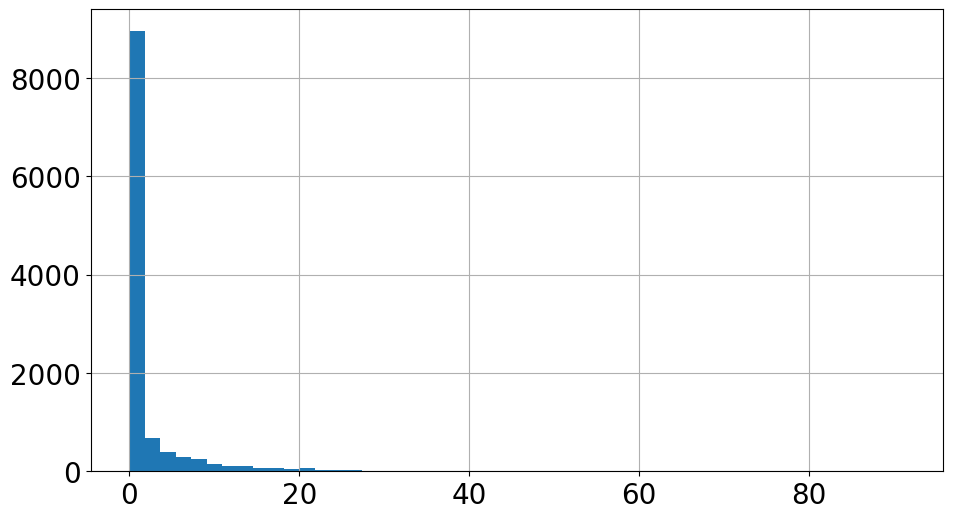

In [7]:
#Plotting the histogram of dataset
plt.figure(figsize=(11, 6))
plt.rc('font', size=20)         # controls default text sizes
plt.rc('axes', titlesize=22)    # fontsize of the axes title
plt.rc('axes', labelsize=22)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=20)   # fontsize of the tick labels
plt.rc('ytick', labelsize=20)  # fontsize of the tick labels
plt.rc('legend', fontsize=22)   # legend fontsize
plt.rc('figure', titlesize=23)  # fontsize of the figure title
series = rainfall.PRCP
series.hist(bins=50)
plt.show()

In [8]:
# Box-Cox Transformation Function
def boxcox1p(data):
  p1data= data+1
  bcdata, bclambda = boxcox(p1data)
  return bcdata, bclambda

In [9]:
# Inverse Box-Cox transformation Function
def inv_boxcox1p(bcdata, bclambda):
  data=inv_boxcox(bcdata, bclambda)-1
  return data

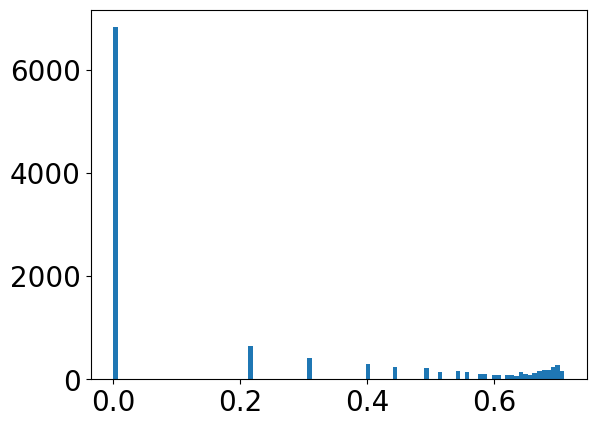

In [10]:
#Calling the Box-Cox transformation function to normalize the data distribution
inv_data, lam_value = boxcox1p(rainfall.PRCP)
plt.hist(inv_data, bins=100)
plt.show()

In [11]:
#Scaling the data for better results
scaler= MinMaxScaler(feature_range=(0,1))
data = inv_data.reshape(-1,1)
scaler.fit(data)
rain_data = scaler.transform(data)[:,0]

In [12]:
#Function for making windowed dataset
from numpy import array
def split_sequences(series, window):
  x, y= list(), list()
  for i in range(len(series)):
    end= i+ window
    if end>len(series)-1:
      break
    seq_x, seq_y= series[i:end], series[end]
    x.append(seq_x)
    y.append(seq_y)
  return array(x), array(y)

In [13]:
#Dividing the dataset into train and test subsets
train_data = rain_data[0:9058]
valid_data = rain_data[9058:]
window_size = 70
x_train, y_train = split_sequences(train_data, window_size)
x_test, y_test = split_sequences(valid_data, window_size)

In [14]:
#Reshaping the test and test input data for LSTM model
x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))

In [15]:
# Building the LSTM model
model = Sequential()
model.add(LSTM(32, input_shape=(window_size, 1), return_sequences=True))
model.add(Dropout(0.5))
model.add(LSTM(32,))
model.add(Dropout(0.5))
model.add(Dense(16, activation='relu'))
model.add(Dense(1, activation='relu'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [16]:
lr_schedule = tf.keras.callbacks.LearningRateScheduler(
    lambda epoch: 1e-7 * 10**(epoch / 40))
optimizer = tf.keras.optimizers.SGD(learning_rate=1e-7, momentum=0.9)
model.compile(loss=tf.keras.losses.Huber(),
              optimizer=optimizer,
              metrics=["mean_squared_error"])
print(model.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 70, 32)         │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 70, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,217 (51.63 KB)

 Trainable params: 13,217 (51.63 KB)

 Non-trainable params: 0 (0.00 B)

None


In [17]:
# LSTM model training phase
print("Starting to fit")
history = model.fit(x_train, y_train, epochs=100, batch_size=60, verbose=1,
                    validation_data=(x_train, y_train), callbacks=[lr_schedule])

Starting to fit
Epoch 1/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 17s 84ms/step - loss: 0.1128 - mean_squared_error: 0.2255 - val_loss: 0.1140 - val_mean_squared_error: 0.2281 - learning_rate: 1.0000e-07
Epoch 2/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 12s 79ms/step - loss: 0.1117 - mean_squared_error: 0.2233 - val_loss: 0.1140 - val_mean_squared_error: 0.2281 - learning_rate: 1.0593e-07
Epoch 3/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 12s 80ms/step - loss: 0.1146 - mean_squared_error: 0.2292 - val_loss: 0.1140 - val_mean_squared_error: 0.2281 - learning_rate: 1.1220e-07
Epoch 4/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 12s 80ms/step - loss: 0.1149 - mean_squared_error: 0.2299 - val_loss: 0.1140 - val_mean_squared_error: 0.2281 - learning_rate: 1.1885e-07
Epoch 5/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 12s 79ms/step - loss: 0.1131 - mean_squared_error: 0.2262 - val_loss: 0.1140 - val_mean_squared_error: 0.2281 - learning_rate: 1.2589e-07
Epoch 6/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 13s 89ms/step - loss: 0.1113 - mean_squared_erro

In [18]:
model.evaluate(x_test, y_test)

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0766 - mean_squared_error: 0.1532


[0.08150698244571686, 0.16301396489143372]

In [19]:
#Predicting the values for test set
result= model.predict(x_test)
result= scaler.inverse_transform(result)
result= inv_boxcox1p(result, lam_value)
y_valid = scaler.inverse_transform(y_test.reshape(-1,1))[:,0]
y_valid = inv_boxcox1p(y_valid, lam_value)
import math
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
lstm_result = result.flatten()
score_lstm = math.sqrt(mean_squared_error(y_valid, lstm_result))
mae_lstm   = mean_absolute_error(y_valid, lstm_result)
r2_lstm    = r2_score(y_valid, lstm_result)
print(f'LSTM RMSE : {score_lstm:.4f}')
print(f'LSTM MAE  : {mae_lstm:.4f}')
print(f'LSTM R2   : {r2_lstm:.4f}')

69/69 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step
LSTM RMSE : 6.2057
LSTM MAE  : 2.3210
LSTM R2   : -0.1308


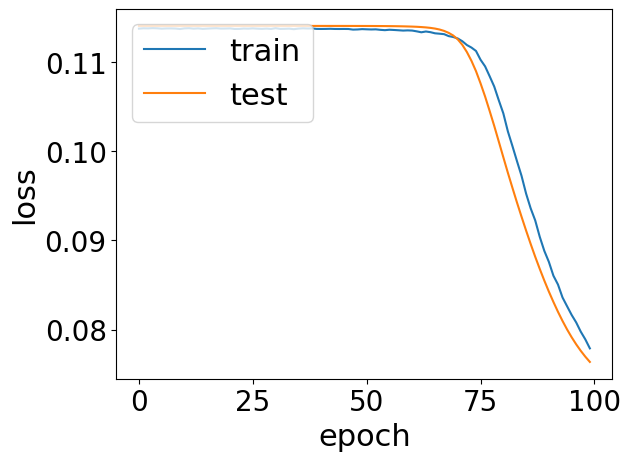

In [20]:
# summarize history for loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [21]:
#Defining average and naive forecast functions
def naiveForecast(x_data):
    # Expected Shape of x_data: (number of samples, number of readings per sample, 1)
    # Shape of forecast: (number of samples, )
    forecast = x_data[:,-1,0]
    return forecast

def avgForecast(x_data):
    # Expected Shape of x_data: (number of samples, number of readings per sample, 1)
    # Shape of forecast: (number of samples, )
    forecast = np.mean(x_data[:,:,0], axis=1)
    return forecast

naive_forecast = naiveForecast(x_test)
avg_forecast = avgForecast(x_test)

In [22]:
avg_forecast= scaler.inverse_transform(avg_forecast.reshape(-1,1))[:,0]
avg_forecast = inv_boxcox1p(avg_forecast, lam_value)
naive_forecast= scaler.inverse_transform(naive_forecast.reshape(-1,1))[:,0]
naive_forecast = inv_boxcox1p(naive_forecast, lam_value)

In [23]:
rmse_avg   = math.sqrt(mean_squared_error(y_valid, avg_forecast))
rmse_naive = math.sqrt(mean_squared_error(y_valid, naive_forecast))
print(f'Average RMSE : {rmse_avg:.4f}')
print(f'Naive RMSE   : {rmse_naive:.4f}')

Average RMSE : 6.1667
Naive RMSE   : 7.9692


---
## XGBoost Model
We train XGBoost on the **same 70-lag features** used by the LSTM, operating in the **MinMax-scaled Box-Cox space** so the pipeline is
identical to the baseline. No changes are made to any baseline code above.


In [24]:
# Install / import XGBoost (already available in Colab)
import xgboost as xgb
print(f'XGBoost version: {xgb.__version__}')

XGBoost version: 3.2.0


In [25]:
# ── XGBoost uses the same windowed data but in 2-D (samples × lag features) ──
# x_train / x_test were reshaped to 3-D for LSTM; we need 2-D for XGBoost.
# We rebuild them directly from the scaled 1-D series.
x_train_xgb = x_train[:, :, 0]   # shape (n_train, 70)
x_test_xgb  = x_test[:, :, 0]    # shape (n_test,  70)
# y_train / y_test are already 1-D (scaled space)
print(f'XGBoost train shape : {x_train_xgb.shape}')
print(f'XGBoost test  shape : {x_test_xgb.shape}')

XGBoost train shape : (8988, 70)
XGBoost test  shape : (2195, 70)


In [26]:
# ── Train XGBoost ──────────────────────────────────────────────────────────
xgb_model = xgb.XGBRegressor(
    objective        = 'reg:squarederror',
    n_estimators     = 150,
    max_depth        = 5,
    learning_rate    = 0.03,
    subsample        = 0.8,
    colsample_bytree = 0.8,
    random_state     = 42,
    n_jobs           = -1,
    early_stopping_rounds = 50,
)

# Use 10 % of training data as an internal validation set for early stopping
n_val = int(len(x_train_xgb) * 0.10)
xgb_model.fit(
    x_train_xgb[:-n_val], y_train[:-n_val],
    eval_set=[(x_train_xgb[-n_val:], y_train[-n_val:])],
    verbose=25,
)
print(f'Best iteration: {xgb_model.best_iteration}')

[0]	validation_0-rmse:0.39427
[25]	validation_0-rmse:0.38860
[50]	validation_0-rmse:0.38731
[75]	validation_0-rmse:0.38704
[100]	validation_0-rmse:0.38665
[125]	validation_0-rmse:0.38679
[149]	validation_0-rmse:0.38684
Best iteration: 99


In [27]:
# ── XGBoost predictions (still in scaled Box-Cox space) ────────────────────
xgb_pred_scaled = xgb_model.predict(x_test_xgb)          # shape (n_test,)

# Inverse-transform: MinMax → Inverse Box-Cox  (same pipeline as baseline)
xgb_pred_bc  = scaler.inverse_transform(xgb_pred_scaled.reshape(-1, 1))[:, 0]
xgb_pred_orig = inv_boxcox1p(xgb_pred_bc, lam_value)

score_xgb = math.sqrt(mean_squared_error(y_valid, xgb_pred_orig))
mae_xgb   = mean_absolute_error(y_valid, xgb_pred_orig)
r2_xgb    = r2_score(y_valid, xgb_pred_orig)
print(f'XGBoost RMSE : {score_xgb:.4f}')
print(f'XGBoost MAE  : {mae_xgb:.4f}')
print(f'XGBoost R2   : {r2_xgb:.4f}')

XGBoost RMSE : 6.1654
XGBoost MAE  : 2.3257
XGBoost R2   : -0.1162


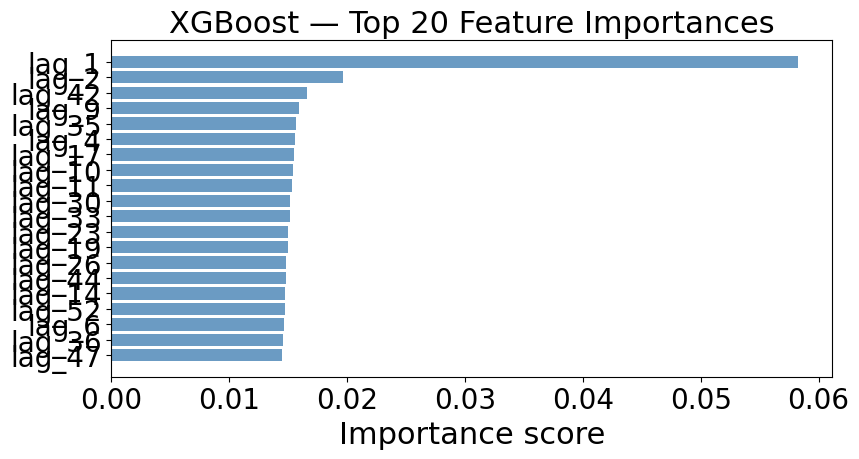

In [28]:
# ── Feature importance (top-20 lag features) ───────────────────────────────
feat_imp = xgb_model.feature_importances_
top20_idx = np.argsort(feat_imp)[-20:][::-1]
top20_names = [f'lag_{window_size - i}' for i in top20_idx]

plt.figure(figsize=(9, 5))
plt.barh(top20_names[::-1], feat_imp[top20_idx[::-1]], color='steelblue', alpha=0.8)
plt.title('XGBoost — Top 20 Feature Importances')
plt.xlabel('Importance score')
plt.tight_layout()
plt.show()

---
## Ensemble: LSTM + XGBoost (Simple Averaging)
Both models predict in the **original (inches) space**. We average their predictions with equal weights (0.5 / 0.5).


In [29]:
# ── Ensemble: simple average of LSTM and XGBoost predictions ──────────────
# Both lstm_result and xgb_pred_orig are already in original precipitation units.
ensemble_pred = 0.5 * lstm_result + 0.5 * xgb_pred_orig

score_ensemble = math.sqrt(mean_squared_error(y_valid, ensemble_pred))
mae_ensemble   = mean_absolute_error(y_valid, ensemble_pred)
r2_ensemble    = r2_score(y_valid, ensemble_pred)
print(f'Ensemble RMSE : {score_ensemble:.4f}')
print(f'Ensemble MAE  : {mae_ensemble:.4f}')
print(f'Ensemble R2   : {r2_ensemble:.4f}')

Ensemble RMSE : 6.1852
Ensemble MAE  : 2.3211
Ensemble R2   : -0.1233


In [30]:
# ── Final comparison table ─────────────────────────────────────────────────
BASELINE_RMSE = 6.181   # from original paper / reference [2]
TARGET_RMSE   = BASELINE_RMSE * 0.90   # 10 % improvement target

improvement = (BASELINE_RMSE - score_ensemble) / BASELINE_RMSE * 100

summary = {
    'Model'       : ['Average (benchmark)', 'Naive (benchmark)',
                     'LSTM (baseline)',     'XGBoost (standalone)',
                     'LSTM-XGBoost Ensemble'],
    'RMSE'        : [rmse_avg,   rmse_naive, score_lstm, score_xgb, score_ensemble],
    'MAE'         : [None,       None,       mae_lstm,   mae_xgb,   mae_ensemble],
    'R2'          : [None,       None,       r2_lstm,    r2_xgb,    r2_ensemble],
}

import pandas as pd
df_summary = pd.DataFrame(summary)
print(df_summary.to_string(index=False, float_format=lambda x: f'{x:.4f}' if x else 'N/A'))
print()
print(f'Baseline RMSE              : {BASELINE_RMSE:.4f}')
print(f'Target  RMSE (−10 %)       : {TARGET_RMSE:.4f}')
print(f'Ensemble RMSE              : {score_ensemble:.4f}')
print(f'Improvement over baseline  : {improvement:.2f} %')
print('Objective met ✅' if score_ensemble <= TARGET_RMSE else 'Objective NOT met — tune hyperparameters ⚠️')

                Model   RMSE    MAE      R2
  Average (benchmark) 6.1667    NaN     NaN
    Naive (benchmark) 7.9692    NaN     NaN
      LSTM (baseline) 6.2057 2.3210 -0.1308
 XGBoost (standalone) 6.1654 2.3257 -0.1162
LSTM-XGBoost Ensemble 6.1852 2.3211 -0.1233

Baseline RMSE              : 6.1810
Target  RMSE (−10 %)       : 5.5629
Ensemble RMSE              : 6.1852
Improvement over baseline  : -0.07 %
Objective NOT met — tune hyperparameters ⚠️


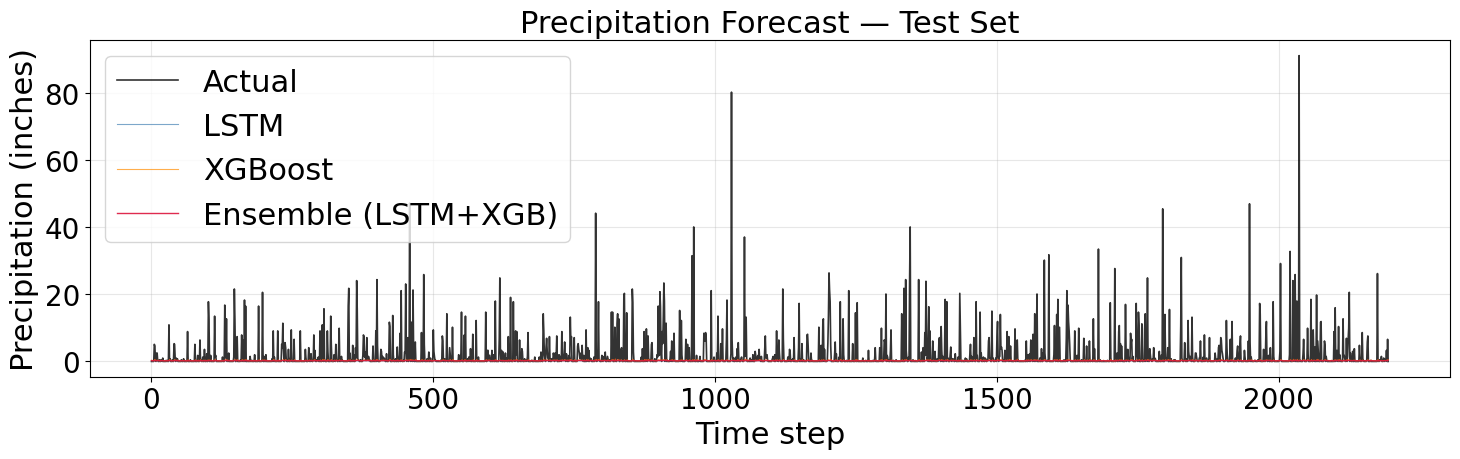

In [31]:
# ── Forecast comparison plot ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(y_valid,        label='Actual',              color='black',      linewidth=1.2, alpha=0.8)
ax.plot(lstm_result,    label='LSTM',                color='steelblue',  linewidth=0.8, alpha=0.7)
ax.plot(xgb_pred_orig,  label='XGBoost',             color='darkorange', linewidth=0.8, alpha=0.7)
ax.plot(ensemble_pred,  label='Ensemble (LSTM+XGB)', color='crimson',    linewidth=1.0, alpha=0.9)
ax.set_title('Precipitation Forecast — Test Set')
ax.set_xlabel('Time step')
ax.set_ylabel('Precipitation (inches)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

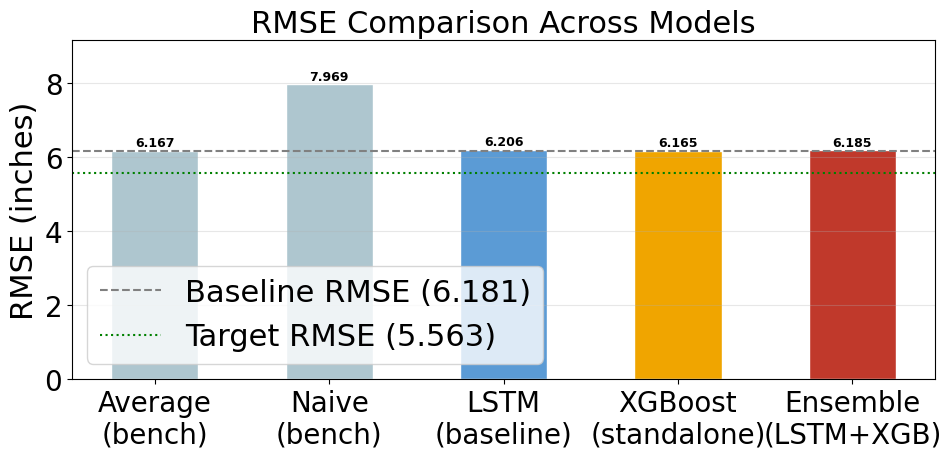

In [32]:
# ── RMSE bar chart ─────────────────────────────────────────────────────────
models = ['Average\n(bench)', 'Naive\n(bench)', 'LSTM\n(baseline)',
          'XGBoost\n(standalone)', 'Ensemble\n(LSTM+XGB)']
rmses  = [rmse_avg, rmse_naive, score_lstm, score_xgb, score_ensemble]
colors = ['#aec6cf', '#aec6cf', '#5b9bd5', '#f0a500', '#c0392b']

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(models, rmses, color=colors, edgecolor='white', width=0.5)
ax.axhline(y=BASELINE_RMSE, color='gray',  linestyle='--', linewidth=1.5,
           label=f'Baseline RMSE ({BASELINE_RMSE})')
ax.axhline(y=TARGET_RMSE,   color='green', linestyle=':',  linewidth=1.5,
           label=f'Target RMSE ({TARGET_RMSE:.3f})')
for bar, val in zip(bars, rmses):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_title('RMSE Comparison Across Models')
ax.set_ylabel('RMSE (inches)')
ax.set_ylim(0, max(rmses) * 1.15)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()